# Credit Card Default Prediction Using Random Forest

### Problem Statement

This project investigates whether a customer's default on a credit card payment in October 2005 can be predicted using financial and repayment information from April-September 2005.

We use the UCI Default of Credit Card Clients dataset, which contains 30,000 customers and 23 input features. Random Forest is our primary classification model, evaluated against simple baselines.

The objective is to identify potential defaulters while considering both missed defaults and false alarms. We evaluate performance using precision, recall, F1-score, ROC-AUC, and average precision rather than accuracy alone.

The study is limited to historical Taiwanese credit card records. Its predictions are not intended for actual lending decisions.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from pathlib import Path

RANDOM_STATE = 42

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 2.3.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


## Dataset Loading

In [2]:
csv_files = list(Path("/kaggle/input").rglob("*.csv"))  #Finds CSV files inside the input folders.

print("Available CSV files:")
for file in csv_files:
    print(file)

df = pd.read_csv(csv_files[0]) #Loads the CSV into a Pandas DataFrame named df

print("\nDataset shape:", df.shape)
display(df.head())

Available CSV files:
/kaggle/input/datasets/uciml/default-of-credit-card-clients-dataset/UCI_Credit_Card.csv

Dataset shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## Inspecting Dataset Structures

In [3]:

print("Column names:")
print(df.columns.tolist()) #Displays all 25 column names, including our target.

print("\nDataset information:")
df.info() #Shows each column's data type and non-null count.

print("\nMissing values:")
print(df.isnull().sum()) #Checks how many missing values exist in each column.

Column names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  

## Examining Categorical and Repayment Status Values
(Some variables are not defined under these categories)

In [4]:
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE"]

pay_cols = ["PAY_0", "PAY_2", "PAY_3",
            "PAY_4", "PAY_5", "PAY_6"]

for col in categorical_cols + pay_cols:
    print(df[col].value_counts().sort_index())  
"""
value_counts() counts how often each value occurs.
sort_index() sorts the output by category code rather than frequency.
"""

SEX
1    11888
2    18112
Name: count, dtype: int64
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        

'\nvalue_counts() counts how often each value occurs.\nsort_index() sorts the output by category code rather than frequency.\n'

1. In Education, there are 14 undocumented values with code 0, so they are grouped with 4,5,6.  which represent (other, unknown, unknown).
2. In Marriage, there are 54 undocumented values with code 0, so they are grouped with 3.  which represents other.

## Target Variable and class distribution

,Count,Percentage
0 - No Default,23364,77.88
1 - Default,6636,22.12


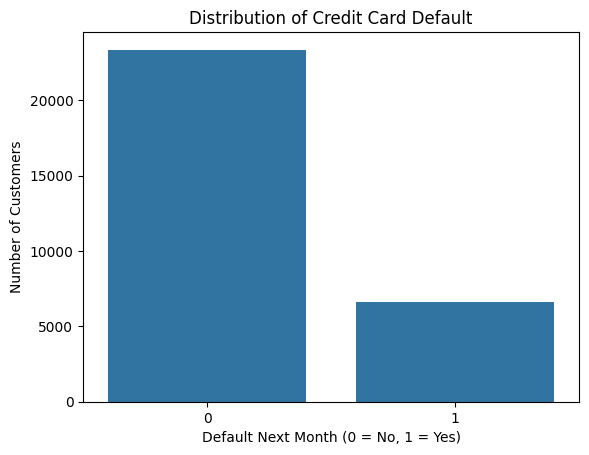

In [5]:
target_col = "default.payment.next.month"

counts = df[target_col].value_counts().sort_index()
percentages = df[target_col].value_counts(
    normalize=True
).sort_index() * 100

summary = pd.DataFrame({
    "Count": counts,
    "Percentage": percentages.round(2)
})

summary.index = ["0 - No Default", "1 - Default"]

display(summary)

sns.countplot(data=df, x=target_col)
plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Next Month (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()


## Default Rates Across Customer Groups

We compare default rates across recent repayment status, education, and marital-status categories. This helps identify patterns in the original data and examine the undocumented categorical codes before grouping them.

In [6]:

for col in ["PAY_0", "EDUCATION", "MARRIAGE"]:
    print(f"\nDefault rate by {col}")

    summary = (
        df.groupby(col)[target_col]
        .agg(Customers="count", Default_Rate="mean")
    )

    summary["Default_Rate"] = (
        summary["Default_Rate"] * 100
    ).round(2)

    display(summary)



Default rate by PAY_0


,Customers,Default_Rate
PAY_0,,
-2,2759,13.23
-1,5686,16.78
0,14737,12.81
1,3688,33.95
2,2667,69.14
3,322,75.78
4,76,68.42
5,26,50.00
6,11,54.55



Default rate by EDUCATION


,Customers,Default_Rate
EDUCATION,,
0,14,0.00
1,10585,19.23
2,14030,23.73
3,4917,25.16
4,123,5.69
5,280,6.43
6,51,15.69



Default rate by MARRIAGE


,Customers,Default_Rate
MARRIAGE,,
0,54,9.26
1,13659,23.47
2,15964,20.93
3,323,26.01


### Observations

Recent repayment status is strongly associated with default. The default rate increases from 12.81% for `PAY_0 = 0` to 69.14% for `PAY_0 = 2`, supporting its relevance as a predictor.

Undocumented `EDUCATION` codes (0, 5, 6) account for only 1.15% of records, while undocumented `MARRIAGE` code 0 accounts for 0.18%. We group these with their respective *Other* categories to retain all customers while avoiding separate categories with limited or unclear meaning. These groupings are practical assumptions rather than evidence that the categories are equivalent.

## Checking Duplicate Records

In [7]:

print("Duplicate IDs:", df["ID"].duplicated().sum())

print("Completely duplicated rows:", df.duplicated().sum())

print("Duplicated feature records:",
      df.drop(columns=["ID", target_col]).duplicated().sum())

Duplicate IDs: 0
Completely duplicated rows: 0
Duplicated feature records: 56


## Statistical Summary of Numerical Features

In [8]:
numerical_cols = [
    "LIMIT_BAL", "AGE",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

display(df[numerical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0


## Grouping Undocumented Categorical Values

In [9]:
df_clean = df.copy()

df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({
    0: 4, 5: 4, 6: 4
})

df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({
    0: 3
})

print("Education categories after grouping:")
print(df_clean["EDUCATION"].value_counts().sort_index())

print("\nMarriage categories after grouping:")
print(df_clean["MARRIAGE"].value_counts().sort_index())

Education categories after grouping:
EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

Marriage categories after grouping:
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


### Preprocessing Decisions

| Decision | Reason |
|---|---|
| Group undocumented education and marriage codes | Retain customers while reducing ambiguity from rare, undocumented categories. |
| Keep repayment-status codes unchanged | Preserve the original repayment information without assuming undocumented codes are equivalent. |
| Keep duplicate feature profiles | Different customer IDs can share identical financial and demographic attributes; no duplicate IDs were found. |
| No feature scaling | Random Forest uses threshold-based tree splits and does not require standardized features. |
These decisions preserve all 30,000 observations and the original 23 predictive features.

## Separating Features and Target

In [10]:

X = df_clean.drop(columns=["ID", "default.payment.next.month"])
y = df_clean["default.payment.next.month"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
print("\nInput features:")
print(X.columns.tolist())


Input features shape: (30000, 23)
Target shape: (30000,)

Input features:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


## Stratified Train–Validation–Test Split

In [11]:

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: Divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Verify split sizes and class distributions
for name, X_part, y_part in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    print(f"\n{name} Set:")
    print("Shape:", X_part.shape)
    print("Class distribution (%):")
    print((y_part.value_counts(normalize=True) * 100).round(2))

# Verify that no customer appears in multiple splits
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("\nAll splits are disjoint.")



Training Set:
Shape: (21000, 23)
Class distribution (%):
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64

Validation Set:
Shape: (4500, 23)
Class distribution (%):
default.payment.next.month
0    77.89
1    22.11
Name: proportion, dtype: float64

Testing Set:
Shape: (4500, 23)
Class distribution (%):
default.payment.next.month
0    77.87
1    22.13
Name: proportion, dtype: float64

All splits are disjoint.


## Majority-Class Baseline

In [12]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

baseline = DummyClassifier(strategy="most_frequent")

# Fit using training data only
baseline.fit(X_train, y_train)

# Evaluate on validation data
y_val_baseline = baseline.predict(X_val)

print("Baseline Accuracy:",
      round(accuracy_score(y_val, y_val_baseline), 4))

print("Baseline Precision:",
      round(precision_score(y_val, y_val_baseline, zero_division=0), 4))

print("Baseline Recall:",
      round(recall_score(y_val, y_val_baseline, zero_division=0), 4))

print("Baseline F1:",
      round(f1_score(y_val, y_val_baseline, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_baseline))


Baseline Accuracy: 0.7789
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0

Confusion Matrix:
[[3505    0]
 [ 995    0]]


## Repayment-Based Rule Baseline

We compare Random Forest against a simple rule that predicts default when the most recent repayment-status code (`PAY_0`) is at least 1. This rule uses only September repayment status and requires no model training.

In [13]:

# Predict default when September repayment status is positive
y_val_rule = (X_val["PAY_0"] >= 1).astype(int)

print("Repayment Rule Baseline — Validation Set")
print("----------------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_rule), 4))
print("Precision:", round(precision_score(y_val, y_val_rule, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_rule, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, y_val_rule, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_rule))


Repayment Rule Baseline — Validation Set
----------------------------------------
Accuracy: 0.78
Precision: 0.5026
Recall: 0.4925
F1 Score: 0.4975

Confusion Matrix:
[[3020  485]
 [ 505  490]]


### Baseline Comparison

The repayment-based rule achieves an F1-score of 0.4975, considerably better than the majority-class baseline, which identifies no defaulters.

The final Random Forest improves validation F1 to 0.5454 and recall from 49.25% to 56.18%. This suggests that combining repayment history with additional financial and demographic features provides some predictive benefit over using September repayment status alone.

## Single Decision Tree Benchmark

A single Decision Tree provides a comparison with Random Forest, which combines predictions from many trees. We use a shallow, regularized tree to limit overfitting and compare both methods on the same validation set.

In [14]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

dt_baseline = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42
)

dt_baseline.fit(X_train, y_train)

y_val_dt = dt_baseline.predict(X_val)
y_val_dt_prob = dt_baseline.predict_proba(X_val)[:, 1]

print("Decision Tree — Validation Set")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_dt), 4))
print("Precision:", round(precision_score(y_val, y_val_dt, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_dt, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, y_val_dt, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_dt_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_val_dt_prob), 4))


Decision Tree — Validation Set
--------------------------------
Accuracy: 0.7824
Precision: 0.5076
Recall: 0.5387
F1 Score: 0.5227
ROC-AUC: 0.76
PR-AUC: 0.5078


### Baseline Comparison

The majority-class baseline achieves 77.89% accuracy but fails to identify any defaulters. A repayment-based rule improves F1 to 0.4975, while a single Decision Tree achieves 0.5227.

Random Forest achieves the highest validation F1 (0.5454) and average precision (0.5480) among the evaluated models. Although the improvement is moderate, the ensemble provides better default detection than these simpler alternatives on our validation set.

## Training the Initial Random Forest

In [15]:

from sklearn.ensemble import RandomForestClassifier

rf_initial = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_initial.fit(X_train, y_train)

print("Initial Random Forest trained successfully!")
print("Number of trees:", len(rf_initial.estimators_))
print("OOB Score:", round(rf_initial.oob_score_, 4))


Initial Random Forest trained successfully!
Number of trees: 100
OOB Score: 0.8153


## Initial Random Forest Performance Evaluation

In [16]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

for name, X_part, y_part in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val)
]:
    y_pred = rf_initial.predict(X_part)
    y_prob = rf_initial.predict_proba(X_part)[:, 1]

    print(f"\n{name} Performance:")
    print("Accuracy:", round(accuracy_score(y_part, y_pred), 4))
    print("Precision:", round(precision_score(y_part, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_part, y_pred, zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_part, y_pred, zero_division=0), 4))
    print("ROC-AUC:", round(roc_auc_score(y_part, y_prob), 4))
    print("PR-AUC:", round(average_precision_score(y_part, y_prob), 4))
    print("Confusion Matrix:")
    print(confusion_matrix(y_part, y_pred))



Training Performance:
Accuracy: 0.9995
Precision: 0.9991
Recall: 0.9985
F1 Score: 0.9988
ROC-AUC: 1.0
PR-AUC: 1.0
Confusion Matrix:
[[16351     4]
 [    7  4638]]

Validation Performance:
Accuracy: 0.8156
Precision: 0.6471
Recall: 0.3648
F1 Score: 0.4666
ROC-AUC: 0.7566
PR-AUC: 0.5282
Confusion Matrix:
[[3307  198]
 [ 632  363]]


## Effect of Maximum Tree Depth on Model Performance

In [17]:

depth_results = []

for depth in [5, 10, 15, 20, None]:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        max_features="sqrt",
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    depth_results.append({
        "max_depth": str(depth),
        "train_accuracy": accuracy_score(y_train, train_pred),
        "val_accuracy": accuracy_score(y_val, val_pred),
        "train_f1": f1_score(y_train, train_pred),
        "val_f1": f1_score(y_val, val_pred),
        "val_recall": recall_score(y_val, val_pred)
    })

depth_results_df = pd.DataFrame(depth_results)

display(depth_results_df.round(4))


,max_depth,train_accuracy,val_accuracy,train_f1,val_f1,val_recall
0,5,0.8197,0.8142,0.4348,0.4137,0.2965
1,10,0.8580,0.8169,0.5858,0.4550,0.3457
2,15,0.9070,0.8184,0.7396,0.4671,0.3598
3,20,0.9505,0.8162,0.8741,0.4548,0.3467
4,None,0.9995,0.8156,0.9988,0.4666,0.3648


## Effect of Minimum Samples per Leaf

In [18]:

leaf_results = []

for leaf_size in [1, 2, 5, 10, 20]:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=leaf_size,
        max_features="sqrt",
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    leaf_results.append({
        "min_samples_leaf": leaf_size,
        "train_accuracy": accuracy_score(y_train, train_pred),
        "val_accuracy": accuracy_score(y_val, val_pred),
        "train_f1": f1_score(y_train, train_pred, zero_division=0),
        "val_f1": f1_score(y_val, val_pred, zero_division=0),
        "val_recall": recall_score(y_val, val_pred, zero_division=0)
    })

leaf_results_df = pd.DataFrame(leaf_results)

display(leaf_results_df.round(4))



,min_samples_leaf,train_accuracy,val_accuracy,train_f1,val_f1,val_recall
0,1,0.9070,0.8184,0.7396,0.4671,0.3598
1,2,0.8970,0.8149,0.7080,0.4494,0.3417
2,5,0.8700,0.8144,0.6231,0.4510,0.3447
3,10,0.8498,0.8149,0.5588,0.4538,0.3477
4,20,0.8342,0.8171,0.5140,0.4610,0.3538


## Effect of Class Weighting on Random Forest

In [19]:

weight_results = []

for leaf_size in [1, 20]:
    for weight in [None, "balanced"]:
        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=leaf_size,
            max_features="sqrt",
            class_weight=weight,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)
        val_prob = model.predict_proba(X_val)[:, 1]

        weight_results.append({
            "min_samples_leaf": leaf_size,
            "class_weight": str(weight),
            "train_f1": f1_score(y_train, train_pred),
            "val_accuracy": accuracy_score(y_val, val_pred),
            "val_precision": precision_score(y_val, val_pred, zero_division=0),
            "val_recall": recall_score(y_val, val_pred),
            "val_f1": f1_score(y_val, val_pred),
            "val_pr_auc": average_precision_score(y_val, val_prob)
        })

weight_results_df = pd.DataFrame(weight_results)

display(weight_results_df.round(4))


,min_samples_leaf,class_weight,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_pr_auc
0,1,None,0.7396,0.8184,0.6654,0.3598,0.4671,0.5437
1,1,balanced,0.8175,0.8060,0.5748,0.4714,0.5179,0.5426
2,20,None,0.5140,0.8171,0.6617,0.3538,0.4610,0.5471
3,20,balanced,0.6214,0.7789,0.5000,0.5769,0.5357,0.5454


## Effect of Feature Sampling on Random Forest Performance

In [20]:

feature_results = []

for leaf_size in [1, 20]:
    for max_feat in ["sqrt", 0.5, None]:

        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=leaf_size,
            max_features=max_feat,
            class_weight="balanced",
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)
        val_prob = model.predict_proba(X_val)[:, 1]

        feature_results.append({
            "min_samples_leaf": leaf_size,
            "max_features": str(max_feat),
            "train_f1": f1_score(y_train, train_pred),
            "val_accuracy": accuracy_score(y_val, val_pred),
            "val_precision": precision_score(y_val, val_pred, zero_division=0),
            "val_recall": recall_score(y_val, val_pred),
            "val_f1": f1_score(y_val, val_pred),
            "val_pr_auc": average_precision_score(y_val, val_prob)
        })

feature_results_df = pd.DataFrame(feature_results)

display(feature_results_df.round(4))


,min_samples_leaf,max_features,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_pr_auc
0,1,sqrt,0.8175,0.8060,0.5748,0.4714,0.5179,0.5426
1,1,0.5,0.8447,0.8062,0.5777,0.4593,0.5118,0.5364
2,1,None,0.8619,0.8087,0.5863,0.4573,0.5138,0.5373
3,20,sqrt,0.6214,0.7789,0.5000,0.5769,0.5357,0.5454
4,20,0.5,0.6459,0.7851,0.5128,0.5658,0.5380,0.5466
5,20,None,0.6649,0.7840,0.5105,0.5598,0.5340,0.5428


## Effect of Number of Trees on Random Forest Performance

In [21]:

tree_results = []

for n_trees in [50, 100, 200, 300]:
    model = RandomForestClassifier(
        n_estimators=n_trees,
        max_depth=15,
        min_samples_leaf=20,
        max_features=0.5,
        class_weight="balanced",
        bootstrap=True,
        oob_score=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    val_prob = model.predict_proba(X_val)[:, 1]

    tree_results.append({
        "n_estimators": n_trees,
        "train_f1": f1_score(y_train, train_pred),
        "val_accuracy": accuracy_score(y_val, val_pred),
        "val_precision": precision_score(y_val, val_pred),
        "val_recall": recall_score(y_val, val_pred),
        "val_f1": f1_score(y_val, val_pred),
        "val_pr_auc": average_precision_score(y_val, val_prob),
        "oob_accuracy": model.oob_score_
    })

tree_results_df = pd.DataFrame(tree_results)

display(tree_results_df.round(4))


,n_estimators,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_pr_auc,oob_accuracy
0,50,0.6469,0.7829,0.5081,0.5678,0.5363,0.5454,0.7820
1,100,0.6459,0.7851,0.5128,0.5658,0.5380,0.5466,0.7833
2,200,0.6491,0.7867,0.5160,0.5668,0.5402,0.5451,0.7860
3,300,0.6473,0.7871,0.5168,0.5709,0.5425,0.5466,0.7867


## Combined Hyperparameter Optimization

In [22]:

from itertools import product

depth_values = [8, 12, 15, 20]
leaf_values = [10, 20, 30]
feature_values = ["sqrt", 0.5]

combined_results = []

for depth, leaf, features in product(
    depth_values, leaf_values, feature_values
):
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=depth,
        min_samples_leaf=leaf,
        max_features=features,
        class_weight="balanced",
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    val_prob = model.predict_proba(X_val)[:, 1]

    combined_results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "max_features": str(features),
        "train_f1": f1_score(y_train, train_pred, zero_division=0),
        "val_accuracy": accuracy_score(y_val, val_pred),
        "val_precision": precision_score(y_val, val_pred, zero_division=0),
        "val_recall": recall_score(y_val, val_pred, zero_division=0),
        "val_f1": f1_score(y_val, val_pred, zero_division=0),
        "val_pr_auc": average_precision_score(y_val, val_prob)
    })

combined_results_df = pd.DataFrame(combined_results)

combined_results_df = combined_results_df.sort_values(
    by="val_f1", ascending=False
).reset_index(drop=True)

display(combined_results_df.round(4))


,max_depth,min_samples_leaf,max_features,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_pr_auc
0,12,10,0.5,0.6625,0.7929,0.5299,0.5618,0.5454,0.5480
1,15,20,0.5,0.6473,0.7871,0.5168,0.5709,0.5425,0.5466
2,15,10,0.5,0.7114,0.7964,0.5392,0.5457,0.5425,0.5472
3,12,10,sqrt,0.6353,0.7851,0.5127,0.5698,0.5397,0.5507
4,12,20,0.5,0.6251,0.7824,0.5071,0.5769,0.5397,0.5467
5,15,10,sqrt,0.6696,0.7900,0.5236,0.5568,0.5397,0.5507
6,20,10,sqrt,0.7014,0.7904,0.5247,0.5548,0.5393,0.5466
7,20,20,0.5,0.6586,0.7864,0.5156,0.5648,0.5391,0.5459
8,20,10,0.5,0.7508,0.7982,0.5446,0.5337,0.5391,0.5467
9,8,20,sqrt,0.5759,0.7796,0.5013,0.5809,0.5382,0.5463


## Final Comparison of Top Configurations

In [23]:

top_configs = [
    {"max_depth": 12, "min_samples_leaf": 10, "max_features": 0.5},
    {"max_depth": 15, "min_samples_leaf": 20, "max_features": 0.5},
    {"max_depth": 15, "min_samples_leaf": 10, "max_features": 0.5}
]

final_comparison = []

for config in top_configs:
    for n_trees in [300, 500, 1000]:

        model = RandomForestClassifier(
            n_estimators=n_trees,
            max_depth=config["max_depth"],
            min_samples_leaf=config["min_samples_leaf"],
            max_features=config["max_features"],
            class_weight="balanced",
            bootstrap=True,
            oob_score=True,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        val_pred = model.predict(X_val)
        val_prob = model.predict_proba(X_val)[:, 1]

        final_comparison.append({
            "max_depth": config["max_depth"],
            "min_samples_leaf": config["min_samples_leaf"],
            "n_estimators": n_trees,
            "val_accuracy": accuracy_score(y_val, val_pred),
            "val_precision": precision_score(y_val, val_pred, zero_division=0),
            "val_recall": recall_score(y_val, val_pred),
            "val_f1": f1_score(y_val, val_pred),
            "val_pr_auc": average_precision_score(y_val, val_prob),
            "oob_accuracy": model.oob_score_
        })

final_comparison_df = pd.DataFrame(final_comparison)

display(
    final_comparison_df.sort_values(
        "val_f1", ascending=False
    ).round(4)
)


,max_depth,min_samples_leaf,n_estimators,val_accuracy,val_precision,val_recall,val_f1,val_pr_auc,oob_accuracy
0,12,10,300,0.7929,0.5299,0.5618,0.5454,0.5480,0.7921
5,15,20,1000,0.7873,0.5172,0.5729,0.5436,0.5474,0.7867
4,15,20,500,0.7873,0.5173,0.5719,0.5432,0.5477,0.7871
3,15,20,300,0.7871,0.5168,0.5709,0.5425,0.5466,0.7867
6,15,10,300,0.7964,0.5392,0.5457,0.5425,0.5472,0.7961
1,12,10,500,0.7918,0.5276,0.5578,0.5423,0.5475,0.7922
7,15,10,500,0.7960,0.5384,0.5427,0.5405,0.5473,0.7961
2,12,10,1000,0.7909,0.5257,0.5558,0.5403,0.5485,0.7926
8,15,10,1000,0.7964,0.5398,0.5387,0.5392,0.5472,0.7974


## Training the Selected Final Random Forest

In [24]:

rf_final = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    max_features=0.5,
    class_weight="balanced",
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train, y_train)

print("Final Random Forest trained successfully!")
print("Number of trees:", len(rf_final.estimators_))
print("OOB Accuracy:", round(rf_final.oob_score_, 4))


Final Random Forest trained successfully!
Number of trees: 300
OOB Accuracy: 0.7921


## Final Model Selection

We evaluated Random Forest configurations by varying tree depth, minimum leaf size, class weighting, feature sampling, and number of trees. Model selection was based primarily on validation F1-score, with recall, average precision, and model complexity also considered.

**Key observations:**

- The initial unrestricted forest achieved nearly perfect training performance but substantially lower validation F1 (0.4666).
- Restricting tree complexity reduced the training–validation performance gap, although it did not consistently improve validation scores.
- Balanced class weighting improved recall and F1 at the default classification threshold of 0.5, while average precision changed much less.
- The leading configurations performed similarly. Increasing the number of trees beyond 300 did not consistently improve validation F1.

**Selected configuration:**

| Parameter | Value |
|---|---|
| Number of trees | 300 |
| Maximum depth | 12 |
| Minimum samples per leaf | 10 |
| Maximum features per split | 0.5 |
| Class weight | balanced |
| Bootstrap | True |
| Random state | 42 |

This configuration achieved a validation F1-score of **0.5454** and average precision of **0.5480**. It was selected before final test evaluation.

Small validation differences do not establish that these hyperparameters are universally optimal. The final test set was reserved for estimating performance on unseen customers.

## Final Test Set Evaluation

In [25]:

# Predictions on the untouched test set
y_test_pred = rf_final.predict(X_test)
y_test_prob = rf_final.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
test_roc_auc = roc_auc_score(y_test, y_test_prob)
test_pr_auc = average_precision_score(y_test, y_test_prob)

print("FINAL TEST SET PERFORMANCE")
print("--------------------------")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"ROC-AUC:   {test_roc_auc:.4f}")
print(f"PR-AUC:    {test_pr_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


FINAL TEST SET PERFORMANCE
--------------------------
Accuracy:  0.7924
Precision: 0.5291
Recall:    0.5663
F1 Score:  0.5470
ROC-AUC:   0.7774
PR-AUC:    0.5535

Confusion Matrix:
[[3002  502]
 [ 432  564]]


## Precision-Recall Curve

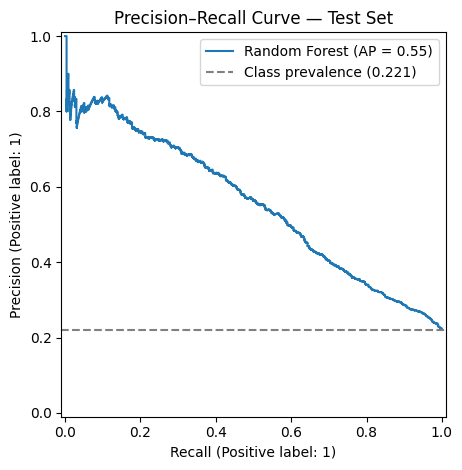

In [26]:

from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob,
    name="Random Forest"
)

plt.axhline(
    y=y_test.mean(),
    color="gray",
    linestyle="--",
    label=f"Class prevalence ({y_test.mean():.3f})"
)

plt.title("Precision–Recall Curve — Test Set")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation

The Random Forest achieves an average precision of 0.5535 on the test set, compared with a default prevalence of approximately 0.221. The precision–recall curve remains above this baseline across most recall values, indicating useful discrimination despite class imbalance.

## Confusion Matrix — Final Test Set

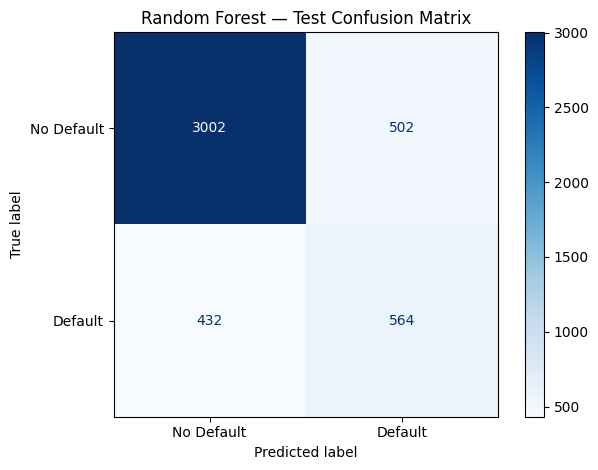

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.show()


## Error Analysis by Recent Repayment Status

In [28]:

error_df = X_test[["PAY_0"]].copy()
error_df["Actual"] = y_test
error_df["Predicted"] = y_test_pred

error_df["Group"] = np.where(
    error_df["PAY_0"] >= 1,
    "Positive delay code",
    "No positive delay code"
)

results = []

for group, data in error_df.groupby("Group"):
    tn, fp, fn, tp = confusion_matrix(
        data["Actual"], data["Predicted"], labels=[0, 1]
    ).ravel()

    results.append({
        "Group": group,
        "Customers": len(data),
        "Actual Defaults": int(tp + fn),
        "Missed Defaults (FN)": int(fn),
        "False Alarms (FP)": int(fp),
        "Recall": round(recall_score(
            data["Actual"], data["Predicted"], zero_division=0
        ), 4),
        "Precision": round(precision_score(
            data["Actual"], data["Predicted"], zero_division=0
        ), 4)
    })

display(pd.DataFrame(results).set_index("Group"))


,Customers,Actual Defaults,Missed Defaults (FN),False Alarms (FP),Recall,Precision
Group,,,,,,
No positive delay code,3468,484,383,152,0.2087,0.3992
Positive delay code,1032,512,49,350,0.9043,0.5695


### Error Analysis Findings

The model detects 90.43% of actual defaulters with a positive September repayment-delay code, compared with only 20.87% among customers without one.

Of the 432 missed defaults, 383 (88.66%) occur among customers without a positive delay code. This suggests that the model relies strongly on recent repayment behaviour and struggles to identify customers who default despite having no recorded positive delay code in September.

This is an important limitation of the model, especially for identifying less obvious default risks.

## Random Forest Feature Importance

Top 10 Important Features:


PAY_0        0.2732
PAY_2        0.1030
LIMIT_BAL    0.0501
PAY_3        0.0497
BILL_AMT1    0.0481
PAY_AMT2     0.0464
PAY_AMT3     0.0429
PAY_AMT1     0.0377
PAY_AMT4     0.0332
BILL_AMT2    0.0330
dtype: float64

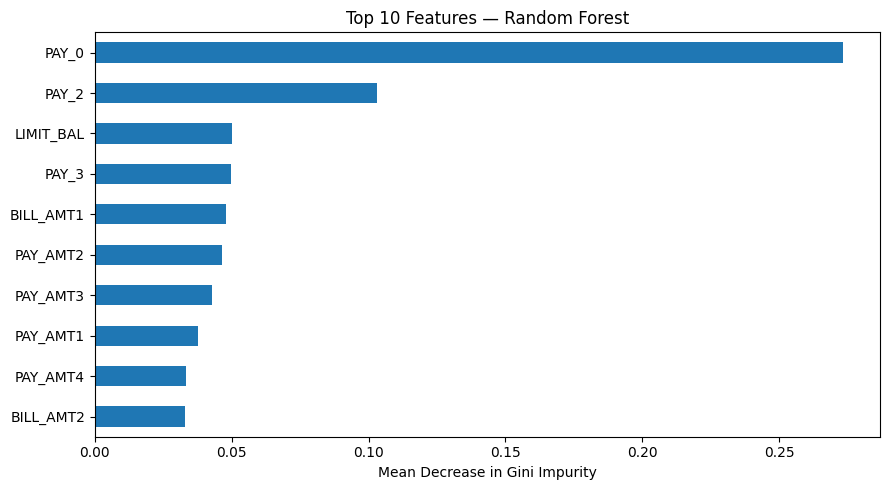

In [29]:

importances = pd.Series(
    rf_final.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 Important Features:")
display(importances.head(10).round(4))

plt.figure(figsize=(9, 5))
importances.head(10).sort_values().plot(kind="barh")
plt.xlabel("Mean Decrease in Gini Impurity")
plt.title("Top 10 Features — Random Forest")
plt.tight_layout()
plt.show()


## Permutation Feature Importance

We measure how much validation performance decreases when individual feature values are shuffled. This provides an additional check on the Random Forest's feature importance.

In [30]:

from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_final, X_val, y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=X_val.columns
).sort_values(ascending=False)

display(perm_importance.head(10).round(4))


PAY_0        0.1912
PAY_2        0.0152
PAY_AMT3     0.0138
BILL_AMT1    0.0134
PAY_5        0.0108
LIMIT_BAL    0.0099
PAY_AMT6     0.0086
PAY_6        0.0064
PAY_4        0.0059
PAY_3        0.0047
dtype: float64

## Threshold-Based Performance Analysis

In [31]:

threshold_results = []

# Use validation predictions, not final test predictions
val_prob = rf_final.predict_proba(X_val)[:, 1]

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,threshold,accuracy,precision,recall,f1,TN,FP,FN,TP
0,0.10,0.2387,0.2248,0.9980,0.3670,81,3424,2,993
1,0.15,0.2993,0.2381,0.9859,0.3836,366,3139,14,981
2,0.20,0.4029,0.2642,0.9528,0.4137,865,2640,47,948
3,0.25,0.5067,0.2938,0.8774,0.4402,1407,2098,122,873
4,0.30,0.6004,0.3337,0.8101,0.4727,1896,1609,189,806
5,0.35,0.6758,0.3780,0.7226,0.4964,2322,1183,276,719
6,0.40,0.7344,0.4328,0.6472,0.5187,2661,844,351,644
7,0.45,0.7647,0.4742,0.5920,0.5266,2852,653,406,589
8,0.50,0.7929,0.5299,0.5618,0.5454,3009,496,436,559
9,0.55,0.8029,0.5614,0.4965,0.5269,3119,386,501,494


## Exporting Project Results

In [32]:

import joblib
import zipfile
from pathlib import Path

out = Path("/kaggle/working/project_exports")
out.mkdir(parents=True, exist_ok=True)

# Final trained Random Forest
joblib.dump(rf_final, out / "random_forest.joblib")

# Real validation results for website interaction
threshold_df.to_json(
    out / "threshold_results.json",
    orient="records",
    indent=2
)

# Feature importance
importances.rename("importance").to_csv(
    out / "feature_importance.csv",
    header=True
)

# Exact customer IDs for reproducibility
for name, subset in [
    ("train", X_train),
    ("validation", X_val),
    ("test", X_test)
]:
    df_clean.loc[subset.index, ["ID"]].to_csv(
        out / f"{name}_ids.csv",
        index=False
    )

# Downloadable ZIP
with zipfile.ZipFile(
    "/kaggle/working/project_exports.zip", "w",
    zipfile.ZIP_DEFLATED
) as z:
    for file in out.iterdir():
        z.write(file, arcname=file.name)

print("Export completed!")
print("Files:", [f.name for f in out.iterdir()])


Export completed!
Files: ['test_ids.csv', 'feature_importance.csv', 'threshold_results.json', 'validation_ids.csv', 'train_ids.csv', 'random_forest.joblib']


# Extra Exports for the website

In [33]:
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
)

out = globals().get("out", Path("/kaggle/working/project_exports"))
out.mkdir(parents=True, exist_ok=True)

# ---- 0. make sure the earlier cells have been run in THIS session ----------
needed = ["rf_final", "rf_initial", "dt_baseline", "baseline",
          "X_val", "y_val", "tree_results_df", "final_comparison_df"]
missing = [name for name in needed if name not in globals()]
if missing:
    raise RuntimeError(
        f"These objects are missing: {missing}. "
        "Use Run > Restart & Run All so every earlier cell is executed first."
    )


# ---- helpers ----------------------------------------------------------------
def r(x, nd=6):
    """Round to plain Python float (JSON cannot store numpy types)."""
    return None if x is None else round(float(x), nd)


def metric_block(y_true, pred, prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy":  r(accuracy_score(y_true, pred)),
        "precision": r(precision_score(y_true, pred, zero_division=0)),
        "recall":    r(recall_score(y_true, pred, zero_division=0)),
        "f1":        r(f1_score(y_true, pred, zero_division=0)),
        "roc_auc":   r(roc_auc_score(y_true, prob)) if prob is not None else None,
        "pr_auc":    r(average_precision_score(y_true, prob)) if prob is not None else None,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }


# ---- 1. bootstrap resamples of the validation set (for uncertainty bands) ---
# Same 1000 resamples are reused for every model / tree count, so comparisons
# are paired. This only measures sampling noise of a 4,500-customer set.
y_arr = y_val.to_numpy().astype(np.int64)
B = 1000
rng = np.random.default_rng(42)
boot_idx = rng.integers(0, len(y_arr), size=(B, len(y_arr)))
y_boot = y_arr[boot_idx]


def f1_interval(pred):
    """95% bootstrap interval for F1 of a fixed set of 0/1 predictions."""
    p = np.asarray(pred).astype(np.int64)[boot_idx]
    tp = (p & y_boot).sum(axis=1)
    fp = (p & (1 - y_boot)).sum(axis=1)
    fn = ((1 - p) & y_boot).sum(axis=1)
    denom = 2 * tp + fp + fn
    f1 = np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)
    lo, hi = np.percentile(f1, [2.5, 97.5])
    return r(lo), r(hi)


# ---- 2. NUMBER-OF-TREES CURVE from the already-trained final forest ---------
# A random forest predicts by AVERAGING the probabilities of its trees, so the
# forest made of the first k trees of rf_final can be evaluated directly,
# with no new training.
Xv = X_val.to_numpy(dtype=np.float32)
tree_probs = np.vstack([t.predict_proba(Xv)[:, 1] for t in rf_final.estimators_])
n_total = tree_probs.shape[0]
running_mean = np.cumsum(tree_probs, axis=0) / np.arange(1, n_total + 1)[:, None]

# sanity check: averaging all trees must reproduce the forest's own output
assert np.allclose(running_mean[-1], rf_final.predict_proba(X_val)[:, 1], atol=1e-6)

candidate_sizes = [1, 2, 3, 5, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300]
sizes = sorted({k for k in candidate_sizes if k <= n_total} | {n_total})

curve = []
for k in sizes:
    prob_k = running_mean[k - 1]
    pred_k = (prob_k > 0.5).astype(int)          # same rule as predict() for 2 classes
    lo, hi = f1_interval(pred_k)
    curve.append({
        "n_estimators": k,
        "val_accuracy":  r(accuracy_score(y_val, pred_k)),
        "val_precision": r(precision_score(y_val, pred_k, zero_division=0)),
        "val_recall":    r(recall_score(y_val, pred_k, zero_division=0)),
        "val_f1":        r(f1_score(y_val, pred_k, zero_division=0)),
        "val_f1_lo": lo, "val_f1_hi": hi,
        "val_pr_auc":    r(average_precision_score(y_val, prob_k)),
    })

# the last curve point must equal the final model's validation F1
f1_final_direct = f1_score(y_val, rf_final.predict(X_val))
assert abs(curve[-1]["val_f1"] - f1_final_direct) < 1e-5

# ---- 3. the separately TRAINED runs that already exist in the notebook ------
selected_cfg = {"max_depth": 12, "min_samples_leaf": 10, "max_features": 0.5,
                "class_weight": "balanced", "bootstrap": True, "random_state": 42}

sel_runs = (final_comparison_df[(final_comparison_df["max_depth"] == 12) &
                                (final_comparison_df["min_samples_leaf"] == 10)]
            .sort_values("n_estimators"))
retrained_selected = [
    {"n_estimators": int(row.n_estimators),
     "val_accuracy": r(row.val_accuracy), "val_precision": r(row.val_precision),
     "val_recall": r(row.val_recall), "val_f1": r(row.val_f1),
     "val_pr_auc": r(row.val_pr_auc), "oob_accuracy": r(row.oob_accuracy)}
    for row in sel_runs.itertuples()
]

retrained_d15 = [
    {"n_estimators": int(row.n_estimators), "train_f1": r(row.train_f1),
     "val_accuracy": r(row.val_accuracy), "val_precision": r(row.val_precision),
     "val_recall": r(row.val_recall), "val_f1": r(row.val_f1),
     "val_pr_auc": r(row.val_pr_auc), "oob_accuracy": r(row.oob_accuracy)}
    for row in tree_results_df.itertuples()
]

tree_json = {
    "description": ("Validation-set performance versus number of trees. "
                    "'curve' = first k trees of the final 300-tree forest (no retraining). "
                    "'retrained_selected_config' = separately trained forests with the "
                    "selected settings. 'retrained_depth15_leaf20' = the earlier "
                    "one-factor experiment (max_depth=15, min_samples_leaf=20)."),
    "selected_config": selected_cfg,
    "bootstrap": {"resamples": B, "interval": "95% percentile, F1 only"},
    "curve": curve,
    "retrained_selected_config": retrained_selected,
    "retrained_depth15_leaf20": retrained_d15,
}
with open(out / "tree_count_results.json", "w") as f:
    json.dump(tree_json, f, indent=2)

tree_results_df.to_csv(out / "tree_count_experiment_50_100_200_300.csv", index=False)

# ---- 4. MODEL COMPARISON on the validation set -------------------------------
rule_pred = (X_val["PAY_0"] >= 1).astype(int).to_numpy()
model_specs = [
    ("majority",      "Majority class",       baseline.predict(X_val),      None),
    ("rule",          "Repayment rule",       rule_pred,                    None),
    ("decision_tree", "Decision tree",        dt_baseline.predict(X_val),
        dt_baseline.predict_proba(X_val)[:, 1]),
    ("rf_initial",    "Initial random forest", rf_initial.predict(X_val),
        rf_initial.predict_proba(X_val)[:, 1]),
    ("rf_final",      "Final random forest",  rf_final.predict(X_val),
        rf_final.predict_proba(X_val)[:, 1]),
]
models = []
for key, name, pred, prob in model_specs:
    pred = np.asarray(pred).astype(int)
    block = metric_block(y_val, pred, prob)
    block["f1_lo"], block["f1_hi"] = f1_interval(pred)
    models.append({"key": key, "name": name, **block})

model_json = {
    "description": "Validation-set results for the baselines and random forests.",
    "n_validation": int(len(y_val)),
    "n_validation_defaults": int(y_val.sum()),
    "models": models,
}
# final test result (only the final model is ever evaluated on the test set)
if all(n in globals() for n in ["y_test", "y_test_pred", "y_test_prob"]):
    model_json["test_rf_final"] = metric_block(y_test, y_test_pred, y_test_prob)

with open(out / "model_comparison.json", "w") as f:
    json.dump(model_json, f, indent=2)

# ---- 5. permutation importance (computed earlier, just not exported yet) -----
if "perm_importance" in globals():
    perm_importance.rename("permutation_importance_drop_in_average_precision").to_csv(
        out / "permutation_importance.csv", header=True)

# ---- 6. rebuild the ZIP so it contains every file in the folder --------------
zip_path = out.parent / "project_exports.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in sorted(out.iterdir()):
        z.write(file, arcname=file.name)

print("Extra exports completed!")
print("Curve points:", [c["n_estimators"] for c in curve])
print("F1 @ final forest (curve vs direct):", curve[-1]["val_f1"], round(f1_final_direct, 6))
if retrained_selected:
    print("F1 @ 300 trees in final_comparison_df:", retrained_selected[0]["val_f1"])
print("ZIP now contains:", [f.name for f in sorted(out.iterdir())])


Extra exports completed!
Curve points: [1, 2, 3, 5, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300]
F1 @ final forest (curve vs direct): 0.545366 0.545366
F1 @ 300 trees in final_comparison_df: 0.545366
ZIP now contains: ['feature_importance.csv', 'model_comparison.json', 'permutation_importance.csv', 'random_forest.joblib', 'test_ids.csv', 'threshold_results.json', 'train_ids.csv', 'tree_count_experiment_50_100_200_300.csv', 'tree_count_results.json', 'validation_ids.csv']
